In [2]:
import numpy as np
import matplotlib.pyplot as plt
from snf.fields import load_field, rotate_by_angles, s21_reciprocity, load_hfss_s21
from snf.plotting import plot_EH_cuts

DATA = '../data/'

# Load Fields

In [3]:
probe_wp = 1
aut_wp = 1

Ea_path = DATA + f'SNF_fields_ports/probe/wp{probe_wp}/E.csv'
Ha_path = DATA + f'SNF_fields_ports/probe/wp{probe_wp}/H.csv'

Eb_path = DATA + f'SNF_fields_ports/AUT/wp{aut_wp}/E.csv'
Hb_path = DATA + f'SNF_fields_ports/AUT/wp{aut_wp}/H.csv'

xyz, Ea = load_field(Ea_path)
_, Ha = load_field(Ha_path)

_, Eb = load_field(Eb_path)
_, Hb = load_field(Hb_path)

# Plot Fields

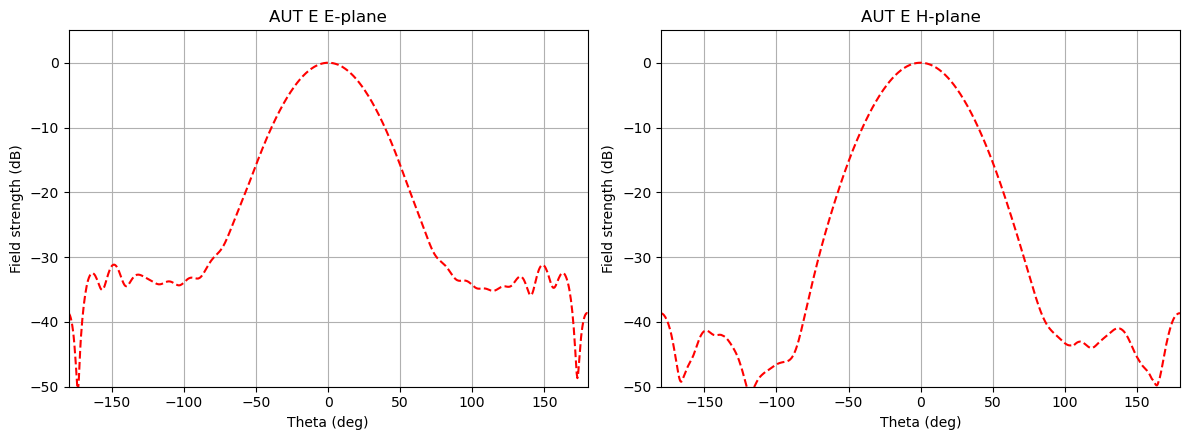

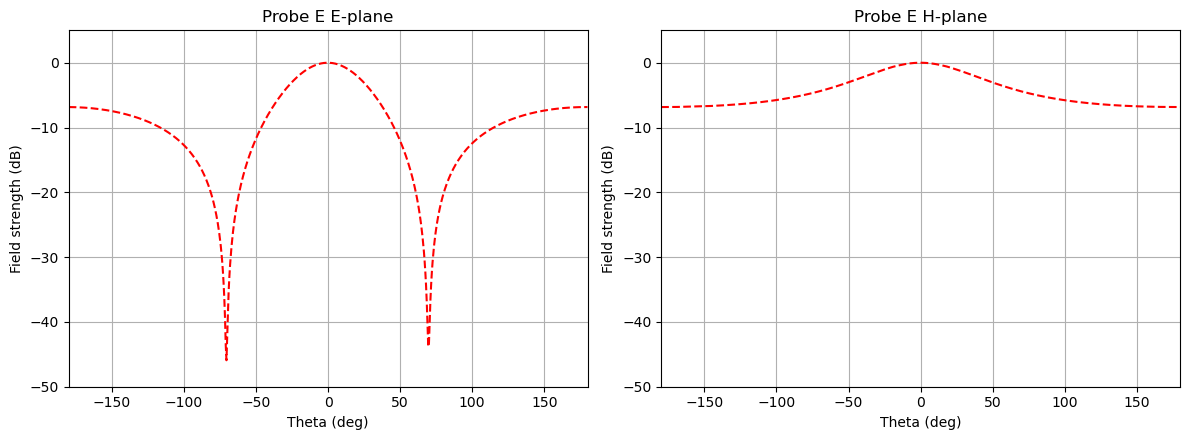

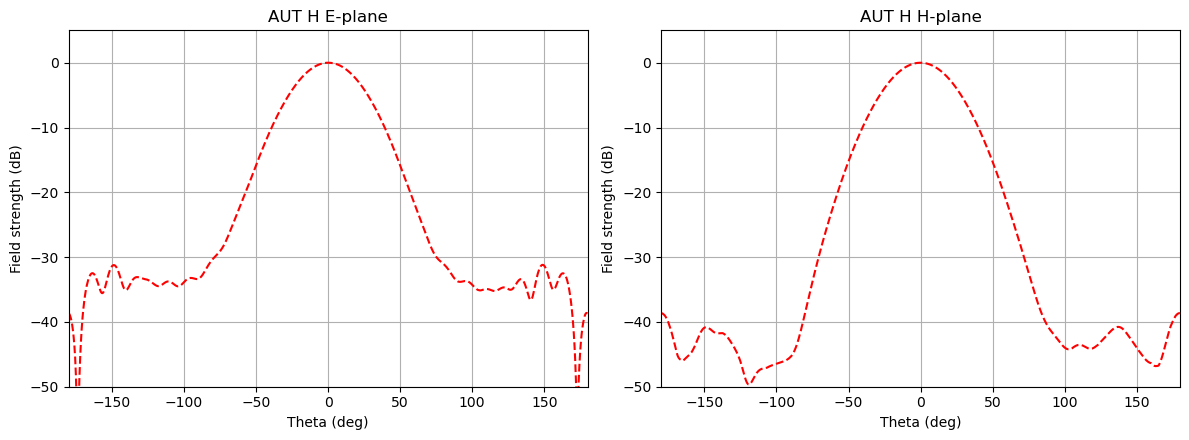

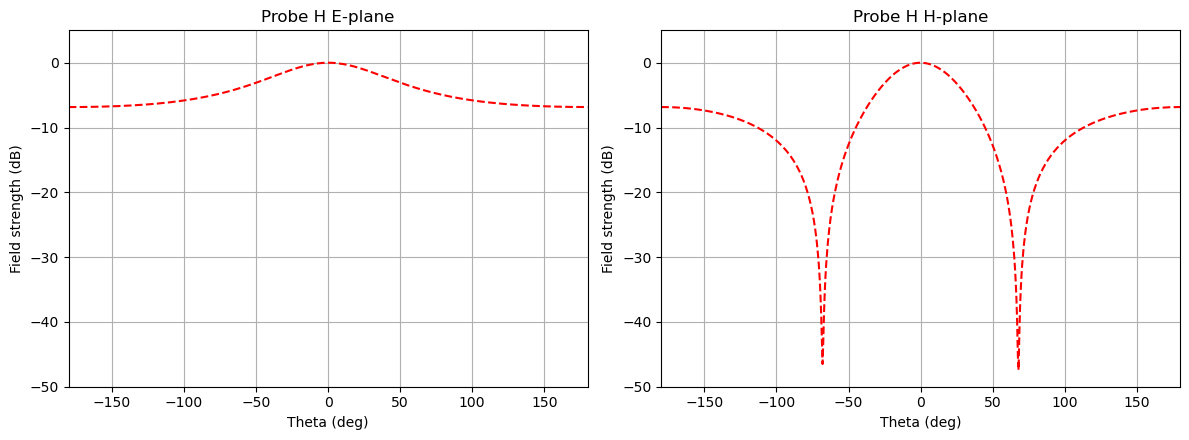

In [4]:
plot_EH_cuts(xyz, Eb, title='AUT E')
plot_EH_cuts(xyz, Ea, title='Probe E')
plot_EH_cuts(xyz, Hb, title='AUT H')
plot_EH_cuts(xyz, Ha, title='Probe H')
plt.show()

# Calculate S21

In [ ]:
# Calculate S21 for each theta

thetas = np.arange(-180, 180 + 1)
phi, chi = 0, 0

s21 = np.zeros(len(thetas), dtype=complex)
for i, theta in enumerate(thetas):
    Ea_rot = rotate_by_angles(xyz, Ea, theta, phi, chi)
    Ha_rot = rotate_by_angles(xyz, Ha, theta, phi, chi)
    s21[i] = s21_reciprocity(xyz, Ea_rot, Ha_rot, Eb, Hb)

In [ ]:
# Plot s21 vs theta

hfss_theta, hfss_db, hfss_phase = load_hfss_s21(DATA + 'S_params.csv', probe_wp, aut_wp)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(thetas, 20 * np.log10(np.abs(s21)), 'r-', lw=1.5, label='Reciprocity calculated')
ax1.plot(hfss_theta, hfss_db, 'ko', label='HFSS calculated')
ax1.set(xlabel='Probe theta (deg)', ylabel='S21 (dB)', title=f'Probe wave port {probe_wp}, AUT wave port {aut_wp}: magnitude')

ax2.plot(thetas, np.degrees(np.angle(s21)), 'r-', lw=1.5, label='Reciprocity calculated')
ax2.plot(hfss_theta, hfss_phase, 'ko', label='HFSS calculated')
ax2.set(xlabel='Probe theta (deg)', ylabel='S21 phase (deg)', title=f'Probe wave port {probe_wp}, AUT wave port {aut_wp}: phase', ylim=(-180, 180))

for ax in (ax1, ax2):
    ax.grid(True)
    ax.legend()

plt.tight_layout()

In [ ]:
# Plot residuals

idx = np.abs(thetas[:, None] - hfss_theta[None, :]).argmin(axis=0)  # nearest reciprocity angle to each HFSS angle
s21_at_hfss = s21[idx]

res_dB = 20 * np.log10(np.abs(s21_at_hfss)) - hfss_db
res_phase = np.degrees(np.angle(s21_at_hfss * np.exp(-1j * np.radians(hfss_phase))))  # wrapped to [-180, 180]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(hfss_theta, res_dB, 'ko', lw=1)
ax1.set(xlabel='Probe theta (deg)', ylabel='Magnitude residual (dB)', title=f'Probe wave port {probe_wp}, AUT wave port {aut_wp}: magnitude residual')

ax2.plot(hfss_theta, res_phase, 'ko', lw=1)
ax2.set(xlabel='Probe theta (deg)', ylabel='Phase residual (deg)', title=f'Probe wave port {probe_wp}, AUT wave port {aut_wp}: phase residual', ylim=(-180, 180))

for ax in (ax1, ax2):
    ax.axhline(0, color='gray', lw=0.8); ax.grid(True)
plt.tight_layout()

main = np.abs(hfss_theta) <= 60
print(f'RMS residual, |theta| <= 60 deg: {np.sqrt(np.mean(res_dB[main]**2)):.2f} dB, {np.sqrt(np.mean(res_phase[main]**2)):.1f} deg')
print(f'RMS residual, all angles:        {np.sqrt(np.mean(res_dB**2)):.2f} dB, {np.sqrt(np.mean(res_phase**2)):.1f} deg')